# TP 2 - Séance 2
## Apprentissage profond appliqué aux images médicales

Équipe #15
- Guindon, Théo (2255253)
- Bererd, Pierre-Louis (2552949)

In [13]:
import datasets
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.manifold import TSNE
from tqdm import tqdm
from collections import Counter

In [14]:
from utils import get_dataloaders, get_embeddings, get_model_and_optimizer, train_epoch, validate


## Exercice 2.1: Exploration des données

Le jeu de données `dataset` est un objet de type [`DatasetDict`](https://huggingface.co/docs/datasets/main/en/package_reference/main_classes#datasets.DatasetDict) organisé comme un `dict` standard en Python, avec des entrées nommées `"train"` et `"test"` et qui contiennent des [`Dataset`](https://huggingface.co/docs/datasets/main/en/package_reference/main_classes#datasets.Dataset) - qui eux contiennent les images et leur label associé.

Vous pouvez interagir avec un `DatasetDict` essentiellement de la même manière qu'avec un `dict` (e.g. les méthodes `keys()`/`values()`/`items()`, aller chercher une entrée avec la notation par crochets `dataset["train"]`, etc.).

Pour interagir avec un `Dataset`, vous pouvez soit aller chercher un exemple donné (e.g. `dataset["train"][0]` qui est un `dict` qui contient une image et son label), soit aller chercher **tous** les labels/images du dataset (e.g. `list(dataset["train"]["label"])`).

<span style="color:red">**Attention!** Si vous essayez de charger toutes les images d'un coup, ça ne machera probablement pas car il y en a beaucoup trop pour la quantité de RAM qui est vraisemblablement disponible sur votre machine.
</span>

In [15]:
dataset = datasets.load_dataset("zacharielegault/Kermany2017-OCT")

# Certaines images sont encodées par erreur comme RGB. On les convertit en grayscale.
dataset["test"] = dataset["test"].map(lambda d: {"image": d["image"].convert("L")})

# Les images sont par défaut encodées en images PIL. On préfère des arrays Numpy qu'on connait bien.
dataset["train"] = dataset["train"].with_format("numpy")
dataset["test"] = dataset["test"].with_format("numpy")

**Q1.** Combien d'images y a-t-il dans chaque sous-ensemble du dataset?

In [16]:
a = len(dataset["train"])
b = len(dataset["test"])

print("Il y a ", a, " images d' entrainement et ", b, " images de test")

Il y a  108309  images d' entrainement et  1000  images de test


**Q2.** Quelles sont les classes représentées dans le dataset? Comment sont-elles représentées?

NB: Vous pouvez utiliser les méthodes `dataset["train"].features["label"].int2str(...)` et `dataset["train"].features["label"].str2int(...)` pour identifier les correspondances.

In [17]:
labels = dataset["train"].features["label"]

for i, name in enumerate(labels.names):
    print(f"Label {i} : {name}")

Label 0 : CNV
Label 1 : DME
Label 2 : DRUSEN
Label 3 : NORMAL


**Q3.** Quel nombre et proportion des images de chaque sous-ensemble appartient aux différentes classes? Affichez un histogramme de la distribution des classes pour chaque sous-ensemble.


train
CNV : 37205 images (34.35 %)
DME : 11348 images (10.48 %)
DRUSEN : 8616 images (7.96 %)
NORMAL : 51140 images (47.22 %)


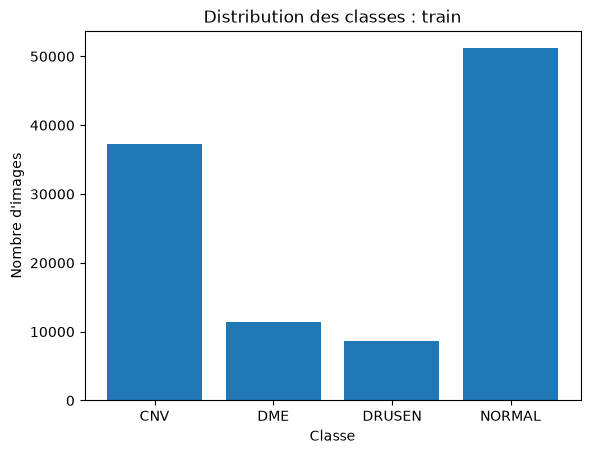


test
CNV : 250 images (25.00 %)
DME : 250 images (25.00 %)
DRUSEN : 250 images (25.00 %)
NORMAL : 250 images (25.00 %)


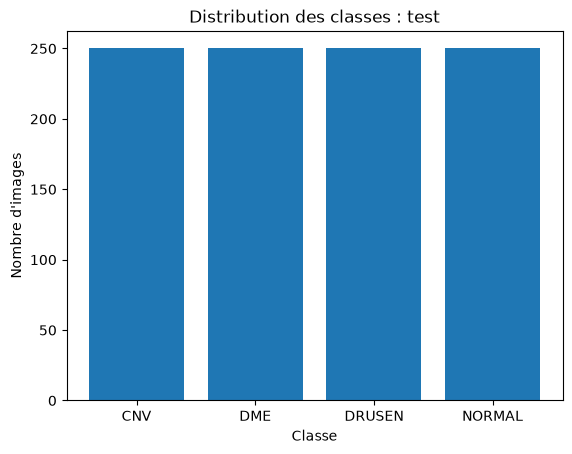

In [18]:
for split in ["train", "test"]:
    labels = dataset[split]["label"]
    counts = np.bincount(labels, minlength=4)
    proportions = counts / len(labels) * 100
    noms = dataset[split].features["label"].names

    print(f"\n{split}")
    for nom, count, prop in zip(noms, counts, proportions):
        print(f"{nom} : {count} images ({prop:.2f} %)")

    plt.bar(noms, counts)
    plt.title(f"Distribution des classes : {split}")
    plt.ylabel("Nombre d'images")
    plt.xlabel("Classe")
    plt.show()

**Q4.** Affichez 2 échantillons de chaque classe. Pour chaque image, affichez l'indice et la classe dans le titre. Décrivez les différences que vous observez entre les classes.

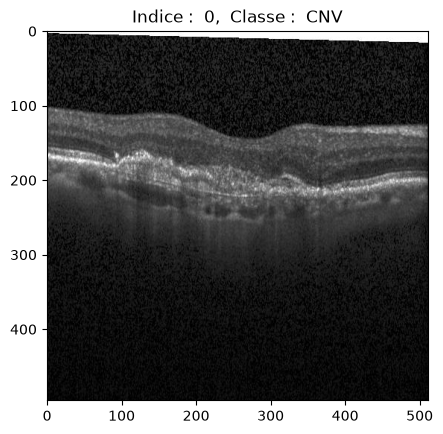

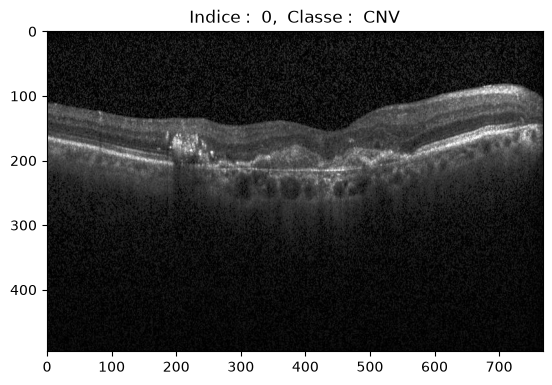

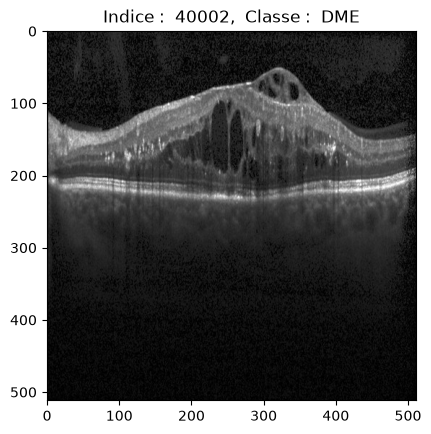

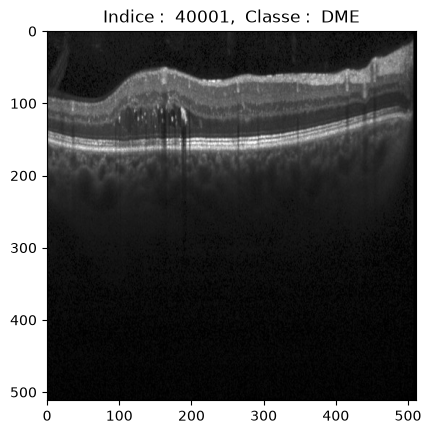

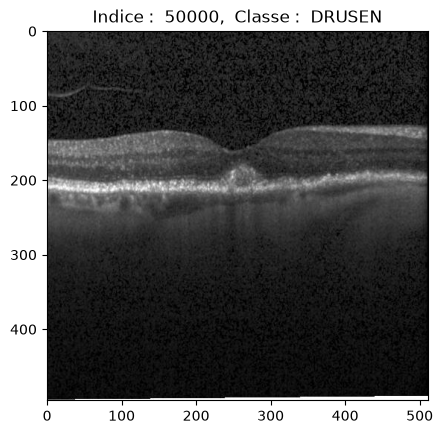

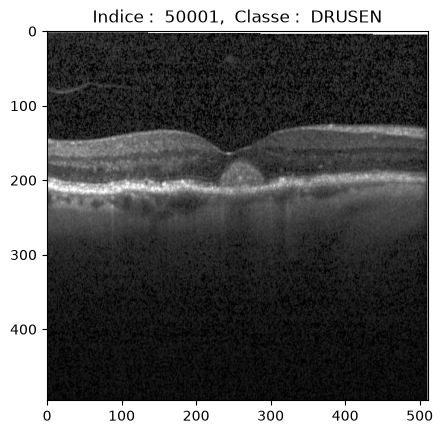

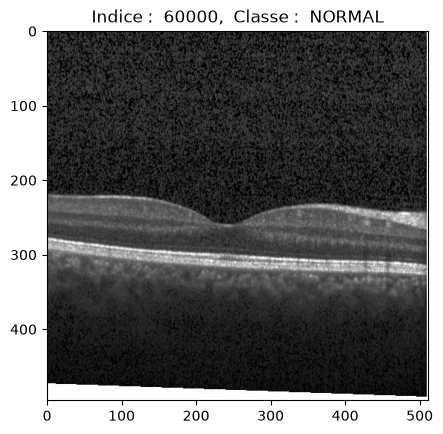

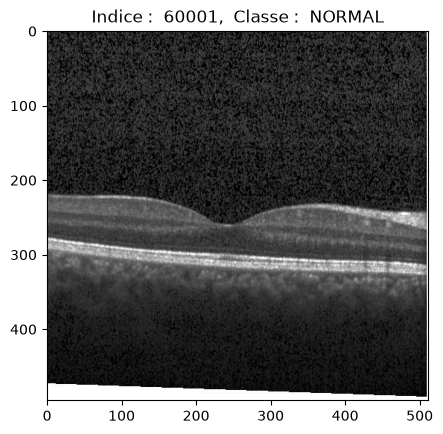

In [ ]:
indice01 = 0
indice02 = 1
indice11 = 40002
indice12 = 40001
indice21 = 50000
indice22 = 50001
indice31 = 60000
indice32 = 60001
img01 = {"image":dataset["train"][indice01]["image"], "indice":indice01, "label":dataset["train"][indice01]["label"]}
img02 = {"image":dataset["train"][indice02]["image"], "indice":indice02, "label":dataset["train"][indice02]["label"]}
img11 = {"image":dataset["train"][indice11]["image"], "indice":indice11, "label":dataset["train"][indice11]["label"]}
img12 = {"image":dataset["train"][indice12]["image"], "indice":indice12, "label":dataset["train"][indice12]["label"]}
img21 = {"image":dataset["train"][indice21]["image"], "indice":indice21, "label":dataset["train"][indice21]["label"]}
img22 = {"image":dataset["train"][indice22]["image"], "indice":indice22, "label":dataset["train"][indice22]["label"]}
img31 = {"image":dataset["train"][indice31]["image"], "indice":indice31, "label":dataset["train"][indice31]["label"]}
img32 = {"image":dataset["train"][indice32]["image"], "indice":indice32, "label":dataset["train"][indice32]["label"]}
images = np.array([img01, img02, img11, img12, img21, img22, img31, img32])


for img in images:
    plt.imshow(img["image"], cmap="gray")
    indice = img["indice"]
    if img["label"]==0:
        classe="CNV"
    if img["label"]==1:
        classe="DME"
    if img["label"]==2:
        classe="DRUSEN"
    if img["label"]==3:
        classe="NORMAL"
    plt.title(f"Indice :  {indice},  Classe :  {classe}")
    plt.show()

On observe plusieurs différences visuelles entre les 4 classes sur les coupes OCT :
-CNV: la couche claire du bas est déformée et soulevée, pas nette ni droite, souvent avec une zone sombre ou un bombement lié à l'accumulation de liquide et aux nouveaux vaisseaux sous la rétine.
-DME : la rétine est épaissie et perd sa symétrie et sa courbure normale au centre, avec des poches sombres (des kystes) à l'intérieur des couches rétiniennes.
- DRUSEN: l'épaisseur globale reste assez proche de la normale, mais la ligne claire du bas présente de petites bosses / ondulations blanchâtres (les dépôts de drusen sous la rétine).
-NORMAL: la rétine est bien symétrique avec un creux régulier au centre, les couches sont bien parallèles et la bande claire du bas est bien droite et continue.

**Q5.** Vous remarquerez que les images ne sont pas toutes de la même taille. Identifiez les tailles d'images et leur fréquence dans chaque sous-ensemble. Que pouvez-vous observer sur leur distribution? En quoi est-ce que des images de tailles différentes peut être un problème?

In [20]:
import io
from PIL import Image
from datasets import Image as HFImage

raw = dataset["train"].with_format(None).cast_column("image", HFImage(decode=False))
tailles = {0: [], 1: [], 2: [], 3: []}
for batch in raw.iter(batch_size=1000):
    for img, lab in zip(batch["image"], batch["label"]):
        w, h = Image.open(io.BytesIO(img["bytes"])).size  # seulement lire l'en-tête
        tailles[lab].append((h, w))

frequences = [Counter(tailles[k]) for k in range(4)]

In [21]:
noms = dataset["train"].features["label"].names
for k, nom in enumerate(noms):
    print(f"{nom} : {dict(frequences[k])}")

CNV : {(496, 512): 19912, (496, 768): 12050, (496, 1536): 5055, (496, 1024): 173, (496, 384): 15}
DME : {(496, 512): 1485, (496, 1536): 374, (496, 768): 816, (512, 512): 8659, (496, 1024): 14}
DRUSEN : {(496, 512): 5371, (496, 768): 2531, (496, 1536): 691, (496, 1024): 23}
NORMAL : {(496, 512): 31269, (496, 768): 14348, (496, 1536): 5340, (496, 1024): 177, (496, 384): 6}


Les images ont des dimensions variables, surtout au niveau de la largeur. Ça pose problème pour entraîner un réseau de neurones, parce qu’il faut pouvoir regrouper les images dans des tenseurs de même taille.

Le fichier utils.py règle ça en redimensionnant à 256x256, puis en recadrant à 224x224.

Par contre ces transformations peuvent faire perdre de l’info ou déformer les structures anatomiques (le redimensionnement étire/écrase l’image si le ratio est pas le même, et le recadrage coupe les bords)

## Exercice 2.2: Entraînement d'un modèle de classification

**Q1**. Créez un modèle qui n'a pas été pré-entraîné (utilisez la valeur par défaut de `pretrained=False`). Calculez la _loss_ initiale du modèle sur 10% des données d'entraînement. Est-ce que la _loss_ initiale est bien ce à quoi vous vous attendiez?

Dans la suite de ce TP, nous allons entraîner plusieurs modèles, puis enregistrer les poids du modèle le plus performant selon deux configurations différentes.

Les fichiers .pt fournis avec ce TP contiennent les poids obtenus lors de notre entraînement. Les analyses et observations présentées dans ce travail reposent sur ces poids sauvegardés. Par conséquent, certaines métriques, notamment l’accuracy, peuvent différer de celles obtenues lors d’une nouvelle exécution du code.

In [22]:
train_loader, val_loader, test_loader = get_dataloaders(
    dataset, batch_size=64, train_subset=0.1, num_workers=0, pin_memory=False
)

In [23]:
model, optimizer = get_model_and_optimizer(pretrained=False)
loss, accuracy = validate(model, train_loader)

print("Loss initiale :", loss)
print("Loss théorique :", np.log(4))

Loss initiale : 1.386294603417295
Loss théorique : 1.3862943611198906


La loss initiale est la même que la valeur théorique, pour l'instant pas de problème

**Q2**. Entraînez votre modèle sur 10% des données d'entraînement (20 époques devraient suffire). Affichez la courbe d'évolution de votre erreur (_loss_) d'entraînement. Au long de votre entraînement, validez la performance de votre modèle sur l'ensemble de validation et affichez la _loss_ et l'_accuracy_ en fonction de l'époque.

Faites le suivi de l'_accuracy_ et identifiez la plus haute valeur obtenue au cours de l'entraînement. Faites une sauvegarde du modèle lorsque vous obtenez cette meilleure _accuracy_.

N.B.: Pour cette question, vous n'avez pas besoin de faire une validation à chaque époque. Vous pouvez choisir un intervalle plus grand (e.g. toutes les 2 époques) pour diminuer le temps de calcul.

In [ ]:
epochs = []
val_losses = []
val_accuracies = []
loss_total = []
best_accuracy = 0

for epoch in range(20):
    # entrainement
    losses = train_epoch(model, train_loader, optimizer)
    loss_total.append(np.mean(losses))
    print(epoch, np.mean(losses))
          
    # validation toutes les 2 époques
    if (epoch + 1) % 2 == 0:
        val_loss, val_accuracy = validate(model, val_loader)

        epochs.append(epoch + 1)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model.state_dict(), "best_model.pt")

print("Meilleure accuracy de validation :", best_accuracy)

0 0.30485052994874695


1 0.2228002707873072


2 0.16285129582150754


3 0.11190088008825454


4 0.08647654142508411


5 0.07112179537916914


... (11 outputs left out)

17 0.021806846460817753


18 0.03458464793790051


19 0.03357816360108497


Meilleure accuracy de validation : 0.8906942392909897


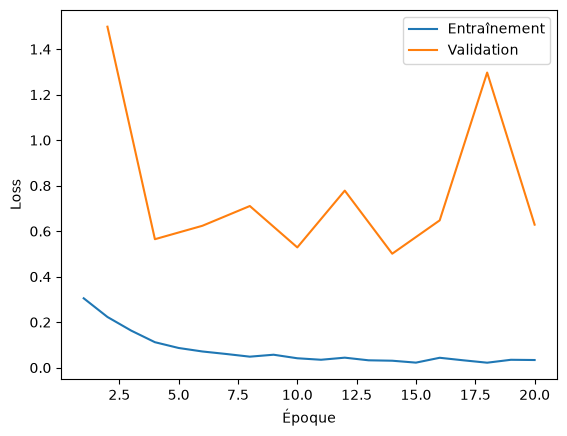

In [ ]:
plt.plot(range(1, 21), loss_total, label="Entraînement")
plt.plot(epochs, val_losses, label="Validation")

plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.show()

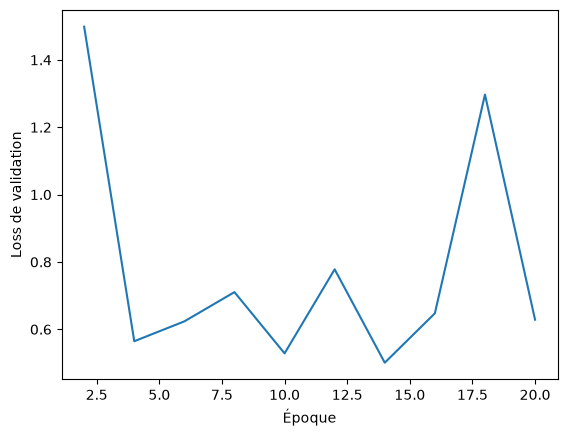

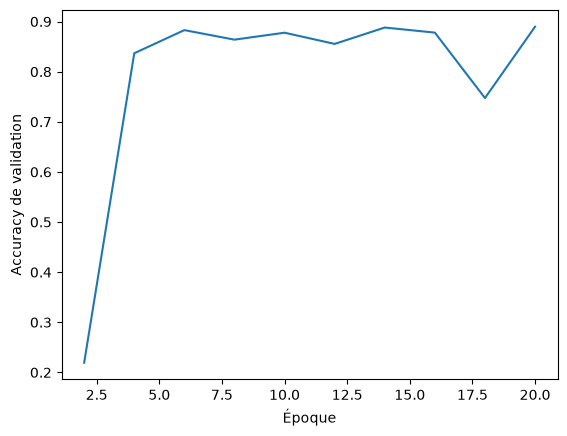

In [ ]:
plt.plot(epochs, val_losses)
plt.xlabel("Époque")
plt.ylabel("Loss de validation")
plt.show()

plt.plot(epochs, val_accuracies)
plt.xlabel("Époque")
plt.ylabel("Accuracy de validation")
plt.show()

Pendant l'entraînement, la loss d'entraînement diminue régulièrement de ~0,30 jusqu'à ~0,02, tandis que la loss de validation descend autour de 0,50–0,60 mais fluctue pas mal (avec un pic à l'époque 18), ce qui montre que le modèle commence à surapprendre sur les 10 % de données. L'accuracy de validation monte rapidement après l'époque 2 puis plafonne autour de 88–89 %, avec une meilleure valeur d'environ 89,1 % sauvegardée dans best_model.pt.

## Apprentissage par transfert

**Q1**. Étant données les différences marquées entre les caractéristiques des images d'ImageNet (des chats, des chiens, des autobus, des spatules, etc.) et les images OCT de la rétine, pensez-vous qu'utiliser un modèle pré-entraîné sur ImageNet va aider vos performances de classification? Expliquez votre raisonnement.

Oui, utiliser un modèle pré-entraîné sur ImageNet devrait aider à apprendre plus rapidement et à obtenir de meilleures performances, même si les images OCT sont très différentes des photos d'imagenet.

En fait, les premières couches d'un réseau convolutif apprennent surtout des caractéristiques visuelles très générales (comme des contours, des contrastes, des lignes, des textures ou des formes simples) qui sont utiles sur presque n'importe quel type d'image, y compris des images médicales.

Au lieu de devoir réapprendre tous ces filtres de base à partir de poids aléatoires, le modèle part déjà avec une bonne base d'extraction de caractéristiques, et le fine-tuning permet ensuite d'adapter les couches plus profondes aux structures spécifiques de la rétine.

**Q2**. Affinez pendant au moins 10 époques un modèle pré-entraîné. Créez le en utilisant l'argument `pretrained=True`. Durant l'entraînement du modèle, faites une sauvegarde du modèle lorsque vous obtenez la meilleure _accuracy_. Affichez les courbes d'évolution de votre _loss_ d'entraînement, et de votre _loss_ et _accuracy_ de validation.

In [ ]:
model_pretrained, optimizer_pretrained = get_model_and_optimizer(pretrained=True)

In [ ]:
epochs = []
val_losses = []
val_accuracies = []
loss_total = []
best_accuracy = 0

for epoch in range(20):
    # Entraînement
    losses = train_epoch(model_pretrained, train_loader, optimizer_pretrained)
    loss_total.append(np.mean(losses))
    print(epoch, np.mean(losses))
          
    # Validation toutes les 2 époques
    if (epoch + 1) % 2 == 0:
        val_loss, val_accuracy = validate(model_pretrained, val_loader)

        epochs.append(epoch + 1)
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)
    
        if val_accuracy > best_accuracy:
            best_accuracy = val_accuracy
            torch.save(model_pretrained.state_dict(), "best_model_pretrained.pt")

print("Meilleure accuracy de validation :", best_accuracy)

0 0.25967598822176086


1 0.0954197428727187


2 0.057569318798064074


3 0.029360989165804725


4 0.023855342585391


5 0.026445750040631245


... (11 outputs left out)

17 0.018742266003337473


18 0.007273489253471464


19 0.010557653163949745


Meilleure accuracy de validation : 0.9562407680945347


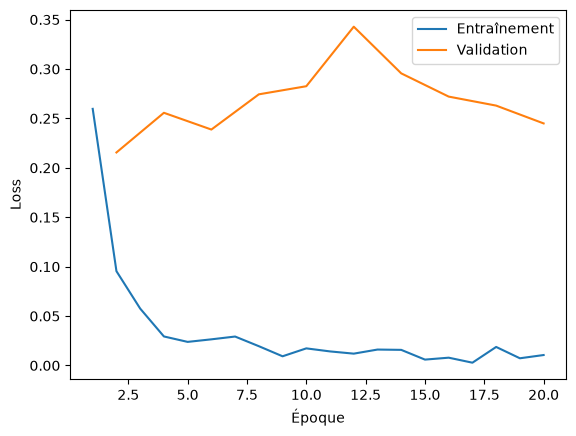

In [ ]:
plt.plot(range(1, 21), loss_total, label="Entraînement")
plt.plot(epochs, val_losses, label="Validation")

plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()
plt.show()

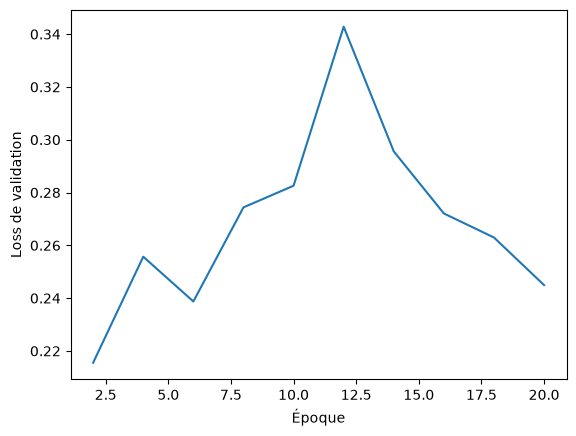

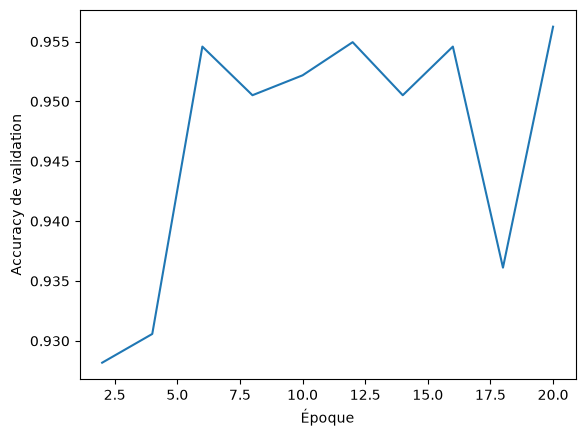

In [ ]:
plt.plot(epochs, val_losses)
plt.xlabel("Époque")
plt.ylabel("Loss de validation")
plt.show()

plt.plot(epochs, val_accuracies)
plt.xlabel("Époque")
plt.ylabel("Accuracy de validation")
plt.show()

**Q3.** Comparez les performances de votre modèle pré-entraîné avec celles de votre modèle non pré-entraîné. Qu'en concluez-vous?

On observe :
- Loss d'entraînement : elle diminue très vite dès les premières époques, d'environ 0,26 à moins de 0,01 (contre ~0,30 à ~0,03 sans pré-entraînement).
- Loss de validation : elle reste beaucoup plus basse et stable (entre 0,22 et 0,34 environ, contre 0,50 à 1,50 pour le modèle non pré-entraîné), même si le fait qu'elle remonte un peu alors que la loss d'entraînement tend vers 0 montre un léger surapprentissage.
- Accuracy de validation : elle démarre déjà autour de 92,8 % dès l'époque 2 et atteint environ 95,6 % à l'époque 20.

Le modèle pré-entraîné sur ImageNet obtient donc de bien meilleures performances et converge beaucoup plus vite que le modèle initialisé aléatoirement, dont l'accuracy maximale plafonnait autour de 89,1 % (soit un gain d'environ 6,5 points de pourcentage).

## Évaluation finale

**Q1**. Évaluez votre meilleur modèle sur l'ensemble de test. Affichez la _loss_ et l'_accuracy_ finale.

In [ ]:
best_model, optimizer = get_model_and_optimizer(pretrained=False)

weights = torch.load("best_model_pretrained.pt", map_location="cpu", weights_only=True)
best_model.load_state_dict(weights)


train_loader, val_loader, test_loader = get_dataloaders(dataset, batch_size=64, train_subset=1)

# Évaluer le modèle sur les données de TEST
test_loss, test_accuracy = validate(best_model, test_loader)

print("Loss de test :", test_loss)
print("Accuracy de test :", test_accuracy)

Loss de test : 0.34587413554266094
Accuracy de test : 0.933


**Q2**. Commentez les performances de votre modèle sur l'ensemble de test et comparez-les à celles obtenues sur l'ensemble de validation.

Le modèle pré-entraîné a 93,3 % d’accuracy et une loss de 0,346 sur le test, contre environ 95,6 % d’accuracy max en validation et une loss d’environ 0,245 à la dernière époque.

Les performances baissent un peu, donc il généralise légèrement moins bien sur le test que sur la validation. Ça peut s’expliquer par un léger surapprentissage, ou par le fait que l'ensemble de validation a la même distribution déséquilibrée que l'entraînement (beaucoup de NORMAL et CNV, peu de DRUSEN), alors que l'ensemble de test est équilibré (25 % par classe).

Mais le modèle garde quand même de bonnes performances sur des données indépendantes, avec une accuracy au-dessus de 93 %.


**Q3**. Pourquoi est-il important de maintenir un ensemble de test séparé de l'ensemble de validation? Que se passerait-il si on n'avait que deux ensembles (entraînement et validation/test) plutôt que trois (entraînement, validation, test)?

Il faut séparer la validation et le test, parce que la validation sert à choisir le meilleur modèle et à régler les hyperparamètres. Le modèle est indirectement optimisé pour ces données-là.

Si on utilisait le même ensemble pour la validation et le test, on risquerait de surestimer les performances sur de nouvelles images.

Un ensemble de test indépendant permet d’évaluer plus objectivement la généralisation du modèle et de repérer un éventuel surapprentissage.

**Q4**. Au sein de l’ensemble de test, identifiez

<!-- | Une image CNV correctement identifiée comme CNV | Une image CNV incorrectement identifiée comme DME | 
 -->


| Une image CNV correctement identifiée comme CNV | Une image CNV incorrectement identifiée comme DME | Une image CNV incorrectement identifiée comme Drusen | Une image CNV incorrectement identifiée comme normale |
|---|---|---|---|
| Une image DME incorrectement identifiée comme CNV | Une image DME correctement identifiée comme DME | Une image DME incorrectement identifiée comme Drusen | Une image DME incorrectement identifiée comme normale |
| Une image Drusen incorrectement identifiée comme CNV | Une image Drusen incorrectement identifiée comme DME | Une image Drusen correctement identifiée comme Drusen | Une image Drusen incorrectement identifiée comme normale |
| Une image normale incorrectement identifiée comme CNV | Une image normale incorrectement identifiée comme DME | Une image normale incorrectement identifiée comme Drusen | Une image normale correctement identifiée comme normale |

In [ ]:
test_loss, test_accuracy, predictions = validate(best_model, test_loader, return_preds=True)

In [ ]:
true_labels = dataset["test"]["label"]
erreurs = []
print("liste des listes avec contradictions")
for i in range(len(predictions)):
    if true_labels[i] == 0 and predictions[i] == 1:
        print("Image trouvée pour vrai 0 et prédit 1 :", i)
        erreurs.append(i)
    if true_labels[i] == 0 and predictions[i] == 2:
        print("Image trouvée pour vrai 0 et prédit 2 :", i)
        erreurs.append(i)
    if true_labels[i] == 0 and predictions[i] == 3:
        print("Image trouvée pour vrai 0 et prédit 3 :", i)
        erreurs.append(i)
    if true_labels[i] == 1 and predictions[i] == 0:
        print("Image trouvée pour vrai 1 et prédit 0 :", i)
        erreurs.append(i)
    if true_labels[i] == 1 and predictions[i] == 2:
        print("Image trouvée pour vrai 1 et prédit 2 :", i)
        erreurs.append(i)
    if true_labels[i] == 1 and predictions[i] == 3:
        print("Image trouvée pour vrai 1 et prédit 3 :", i)
        erreurs.append(i)
    if true_labels[i] == 2 and predictions[i] == 0:
        print("Image trouvée pour vrai 2 et prédit 0 :", i)
        erreurs.append(i)
    if true_labels[i] == 2 and predictions[i] == 1:
        print("Image trouvée pour vrai 2 et prédit 1 :", i)
        erreurs.append(i)
    if true_labels[i] == 2 and predictions[i] == 3:
        print("Image trouvée pour vrai 2 et prédit 3 :", i)
        erreurs.append(i)
    if true_labels[i] == 3 and predictions[i] == 0:
        print("Image trouvée pour vrai 3 et prédit 0 :", i)
        erreurs.append(i)
    if true_labels[i] == 3 and predictions[i] == 1:
        print("Image trouvée pour vrai 3 et prédit 1 :", i)
        erreurs.append(i)
    if true_labels[i] == 3 and predictions[i] == 2:
        print("Image trouvée pour vrai 3 et prédit 2 :", i)
        erreurs.append(i)

liste des listes avec contradictions
Image trouvée pour vrai 0 et prédit 1 : 14
Image trouvée pour vrai 0 et prédit 1 : 19
Image trouvée pour vrai 0 et prédit 1 : 57
Image trouvée pour vrai 0 et prédit 1 : 160
Image trouvée pour vrai 0 et prédit 1 : 221
Image trouvée pour vrai 2 et prédit 0 : 515
Image trouvée pour vrai 2 et prédit 3 : 519
Image trouvée pour vrai 2 et prédit 3 : 520
Image trouvée pour vrai 2 et prédit 0 : 524
Image trouvée pour vrai 2 et prédit 1 : 528
Image trouvée pour vrai 2 et prédit 3 : 531
Image trouvée pour vrai 2 et prédit 0 : 535
Image trouvée pour vrai 2 et prédit 0 : 543
Image trouvée pour vrai 2 et prédit 0 : 545
Image trouvée pour vrai 2 et prédit 0 : 546
Image trouvée pour vrai 2 et prédit 1 : 547
Image trouvée pour vrai 2 et prédit 1 : 552
Image trouvée pour vrai 2 et prédit 0 : 559
Image trouvée pour vrai 2 et prédit 0 : 563
Image trouvée pour vrai 2 et prédit 0 : 567
Image trouvée pour vrai 2 et prédit 0 : 568
Image trouvée pour vrai 2 et prédit 0 : 57

Ce code permet de repérer les indices des images de test qui sont mal prédites par le modèle pour remplir la grille 4x4.

On remarque que plusieurs cases hors-diagonale n'ont aucun exemple (« Aucun exemple » sur la figure). Par exemple, aucune image DME n'est mal classée dans le test, et le modèle ne confond jamais NORMAL avec CNV ou DRUSEN. Ça montre que les pathologies très marquées (comme les poches de liquide du DME ou les gros soulèvements du CNV) sont bien reconnues.

À l'inverse, presque toutes les erreurs viennent de la classe DRUSEN (label 2), qui est parfois confondue avec CNV, DME ou NORMAL. En regardant les images de la 3e ligne de la grille, ça se comprend visuellement : les petits dépôts de drusen forment seulement de légères bosses sur la couche du bas, donc un petit drusen ressemble beaucoup à une rétine normale (indice 715), tandis qu'un drusen plus gros peut ressembler à un début de CNV ou de DME (indices 515 et 639). En plus, DRUSEN est la classe la moins représentée dans le jeu d'entraînement (environ 8 % des images), ce qui explique que le modèle ait plus de mal sur cette classe.

In [ ]:
print("exemples de bonnes prédictions pour chaque cas")
for i in range(len(predictions)):
    if true_labels[i] == 0 and predictions[i] == 0:
        print("Image trouvée pour vrai 0 et prédit 0 :", i)
        break
for i in range(len(predictions)):
    if true_labels[i] == 1 and predictions[i] == 1:
        print("Image trouvée pour vrai 1 et prédit 1 :", i)
        break
for i in range(len(predictions)):
    if true_labels[i] == 2 and predictions[i] == 2:
        print("Image trouvée pour vrai 2 et prédit 2 :", i)
        break

for i in range(len(predictions)):
    if true_labels[i] == 3 and predictions[i] == 3:
        print("Image trouvée pour vrai 3 et prédit 3 :", i)
        break

exemples de bonnes prédictions pour chaque cas
Image trouvée pour vrai 0 et prédit 0 : 0
Image trouvée pour vrai 1 et prédit 1 : 250
Image trouvée pour vrai 2 et prédit 2 : 500
Image trouvée pour vrai 3 et prédit 3 : 750


In [ ]:
indice_dic = {"01":19, "20":515, "21":639, "23":715, "31":802, "00":0, "11":250, "22":500, "33":750}

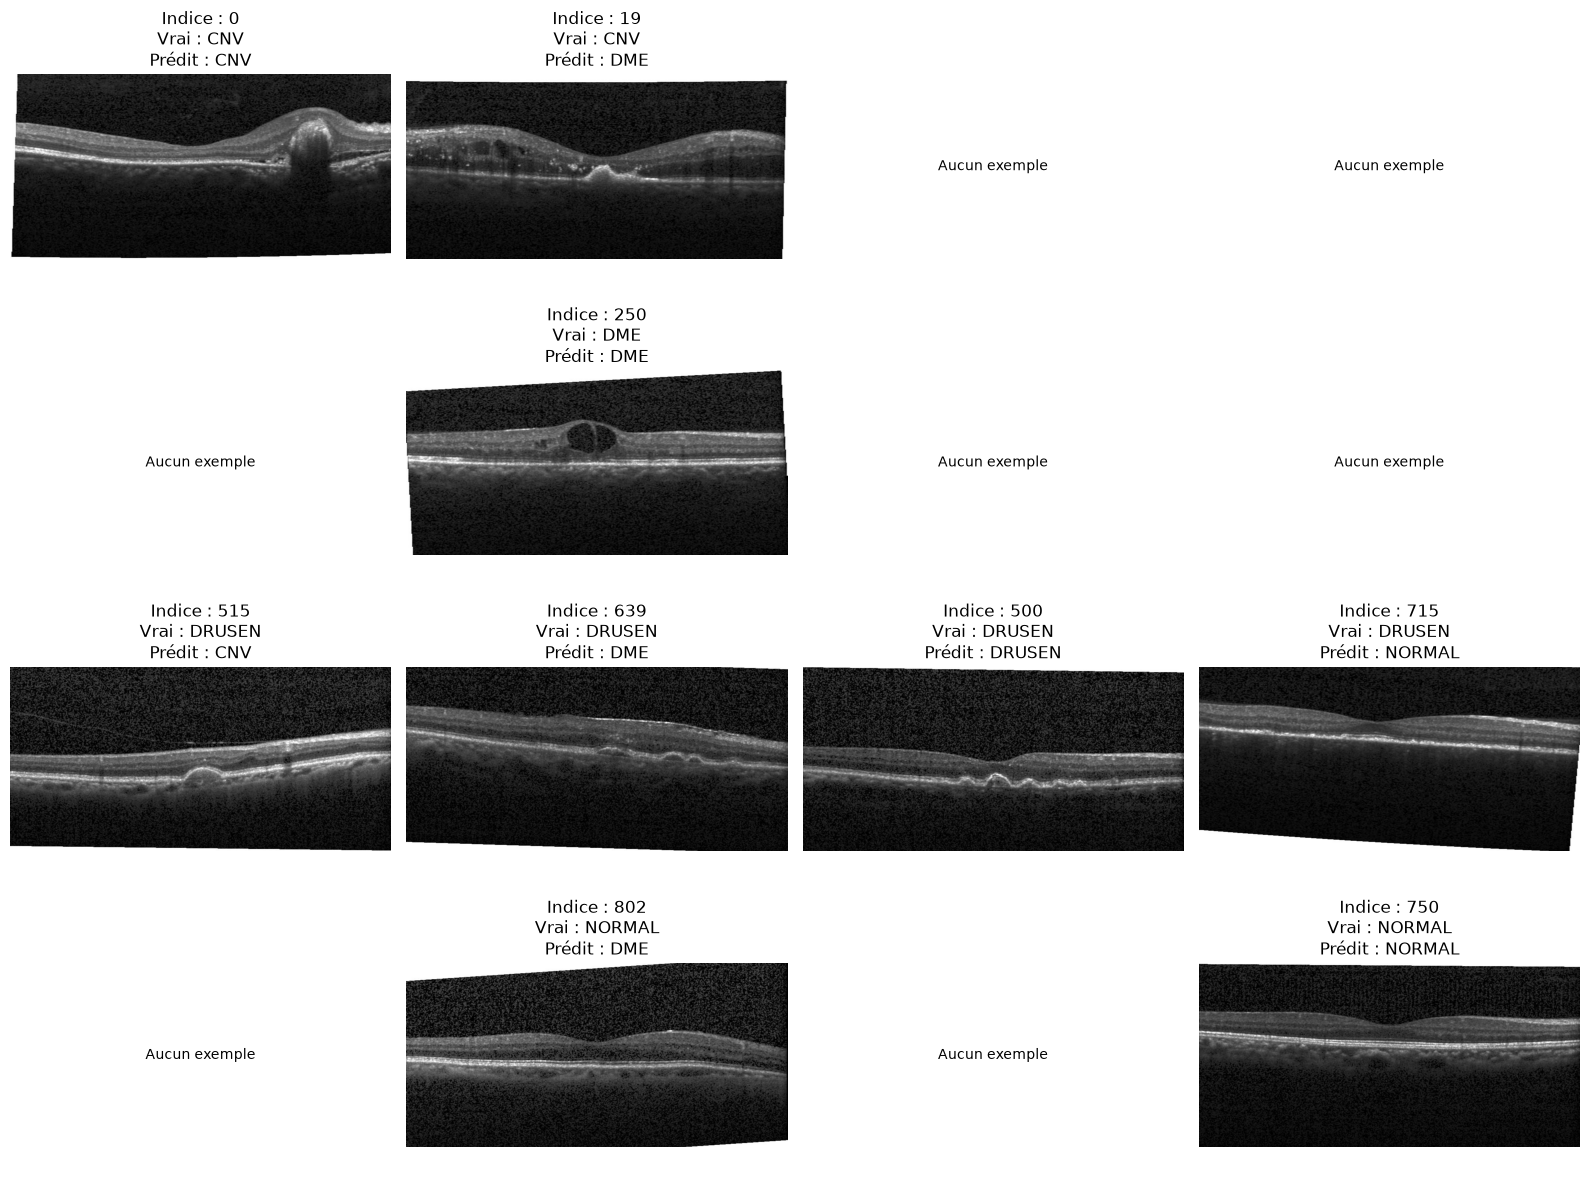

In [ ]:
noms = dataset["test"].features["label"].names

fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for vrai in range(4):
    for predit in range(4):

        ax = axes[vrai, predit]
        cle = f"{vrai}{predit}"

        if cle in indice_dic:
            indice = indice_dic[cle]
            img = dataset["test"][indice]["image"]

            ax.imshow(img, cmap="gray")
            ax.set_title(
                f"Indice : {indice}\n"
                f"Vrai : {noms[vrai]}\n"
                f"Prédit : {noms[predit]}"
            )
        else:
            ax.text(0.5, 0.5, "Aucun exemple",
                    ha="center", va="center")

        ax.axis("off")

plt.tight_layout()
plt.show()

**Q5**. Au vu des performances de votre meilleur modèle sur les données de test, seriez-vous à l'aise d'intégrer ce modèle dans des protocoles cliniques pour aider au diagnostic? Justifiez votre réponse.

Malgré une accuracy de 93,3 % sur les données de test, il serait prématuré d'intégrer directement ce modèle dans un protocole clinique sans validation supplémentaire.
En effet, certaines erreurs de classification peuvent avoir des conséquences importantes, notamment les faux négatifs qui risquent de retarder la prise en charge d'un patient malade. Les faux positifs peuvent également conduire à des examens inutiles.
On remarque notamment que le modèle rencontre davantage de difficultés avec la classe Drusen, ce qui montre que ses performances ne sont pas homogènes entre les différentes pathologies.
Le modèle pourrait être intéressant comme outil d'aide au diagnostic, mais il nécessiterait des évaluations supplémentaires sur des données indépendantes et diversifiées, ainsi qu'une supervision médicale avant toute utilisation clinique.

## Visualisation de l'espace latent

**Q1**. Utilisez la fonction `get_embeddings` pour extraire les _vecteurs latents_ des images de l'ensemble de test issus
1. d'un modèle aléatoirement initialisé;
2. d'un modèle pré-entraîné sur ImageNet, mais non affiné;
3. de votre modèle entraîné (sans pré-entraînement);
4. de votre modèle affiné (avec pré-entraînement).

In [ ]:
model1, optimizer1 = get_model_and_optimizer(pretrained=False)
embeddings1 = get_embeddings(model1, test_loader)

In [ ]:
model2, optimizer2 = get_model_and_optimizer(pretrained=True)
embeddings2 = get_embeddings(model2, test_loader)

In [ ]:
model3, optimizer3 = get_model_and_optimizer(pretrained=False)
weights = torch.load("best_model.pt", map_location="cpu", weights_only=True)
model3.load_state_dict(weights)
embeddings3 = get_embeddings(model3, test_loader)

In [ ]:
model4, optimizer4 = get_model_and_optimizer(pretrained=False)
weights = torch.load("best_model_pretrained.pt", map_location="cpu", weights_only=True)
model4.load_state_dict(weights)
embeddings4 = get_embeddings(model4, test_loader)

In [ ]:
print(embeddings1.shape)
print(embeddings2.shape)
print(embeddings3.shape)
print(embeddings4.shape)

torch.Size([1000, 960])
torch.Size([1000, 960])
torch.Size([1000, 960])
torch.Size([1000, 960])


**Q2**. Pour chacun des trois ensembles de vecteurs latents obtenus à la question précédente, utilisez la méthode t-SNE pour réduire la dimensionnalité des vecteurs à 2D. Affichez les résultats dans un graphique de dispersion (_scatter plot_), où chaque point représente une image, et où la couleur du point indique la classe de l'image. Commentez vos observations.

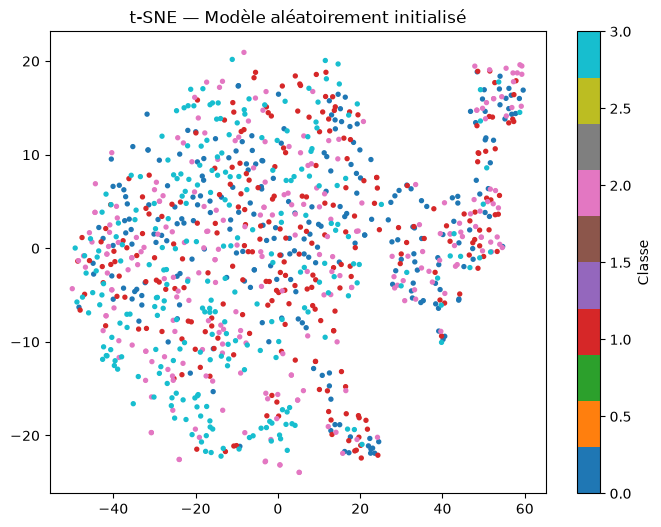

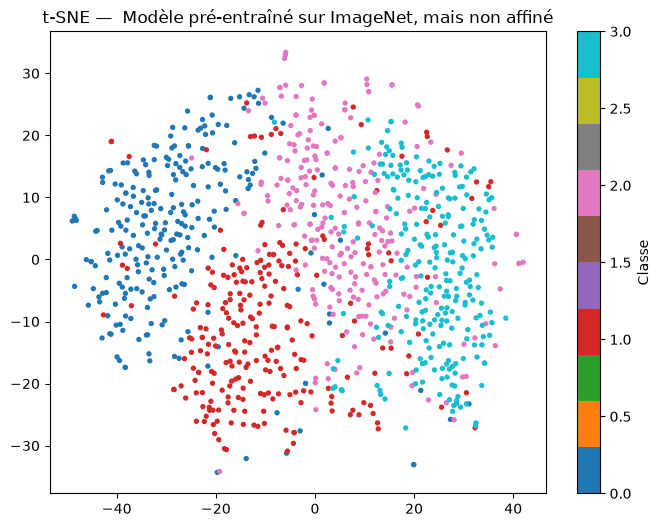

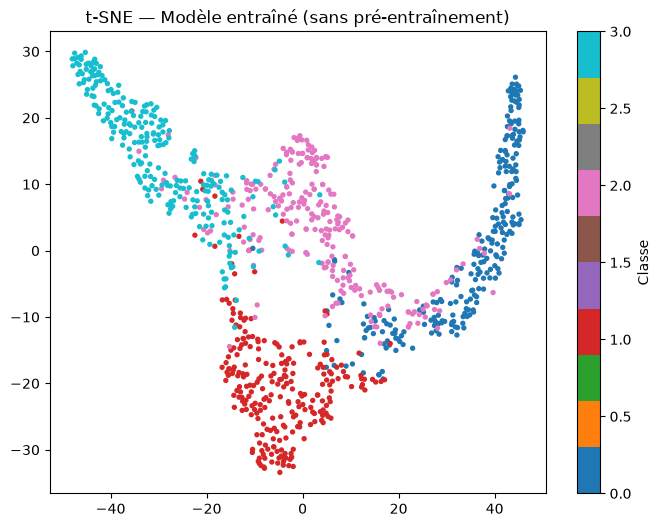

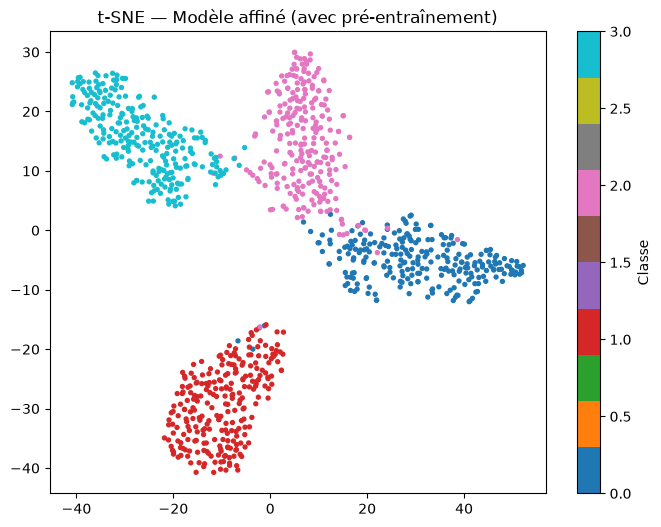

In [ ]:
tsne = TSNE(n_components=2, random_state=42)
projection1 = tsne.fit_transform(embeddings1.numpy())
projection2 = tsne.fit_transform(embeddings2.numpy())
projection3 = tsne.fit_transform(embeddings3.numpy())
projection4 = tsne.fit_transform(embeddings4.numpy())
labels = np.array(dataset["test"]["label"])

plt.figure(figsize=(8, 6))
plt.scatter(projection1[:, 0], projection1[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE — Modèle aléatoirement initialisé")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(projection2[:, 0], projection2[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE —  Modèle pré-entraîné sur ImageNet, mais non affiné")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(projection3[:, 0], projection3[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE — Modèle entraîné (sans pré-entraînement)")
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(projection4[:, 0], projection4[:, 1], c=labels, cmap="tab10", s=8)
plt.colorbar(label="Classe")
plt.title("t-SNE — Modèle affiné (avec pré-entraînement)")
plt.show()

Les projections t-SNE montrent que les représentations latentes changent selon l'entraînement des modèles. Le modèle initialisé au hasard arrive pas à bien distinguer les 4 classes, elles sont très mélangées dans l'espace latent. Le modèle pré-entraîné sur ImageNet mais pas affiné est mieux organisé, même si les classes restent en partie mélangées.

Après l'entraînement sur les images OCT, les classes sont beaucoup mieux séparées. C'est surtout visible pour le modèle pré-entraîné puis affiné, qui a des groupes plus distincts et moins de chevauchements.

Ça suggère que le pré-entraînement sur ImageNet donne des caractéristiques visuelles pertinentes, qui sont ensuite adaptées aux images médicales pendant le fine-tuning. Ça colle avec les meilleures performances de classification du modèle pré-entraîné. Par contre faut garder en tête que t-SNE réduit les représentations de 960 à 2 dimensions, donc on garde pas toute l'info de l'espace latent.